# Q4. Phúc lợi nào phổ biến nhất? Lương cao có đi kèm nhiều phúc lợi hơn?
**Người phụ trách:** Tiến

**Phương pháp:** phúc lợi là văn bản tự do (~73.000 cách viết) → gom về 16 nhóm chuẩn bằng regex (`src/taxonomy.py`,
có test). Tính tỉ lệ tin có từng nhóm; so sánh theo nhóm lương (tứ phân vị); tương quan Spearman giữa số nhóm phúc lợi
và lương.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.cleaning import load_clean, EXPERIENCE_LEVELS, REGIONS, CATEGORY_LABELS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_clean()
df["cat"] = df["category"].map(CATEGORY_LABELS)
# Tập có lương hợp lệ: bỏ "Thoả thuận" và ngoại lai
sal = df[~df["salary_negotiable"] & ~df["salary_outlier"]].copy()
print(f"Tất cả tin: {len(df):,} | Tin có lương hợp lệ: {len(sal):,}")

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

Tất cả tin: 36,457 | Tin có lương hợp lệ: 25,796


Tin có ít nhất 1 nhóm phúc lợi nhận diện được: 95.9%


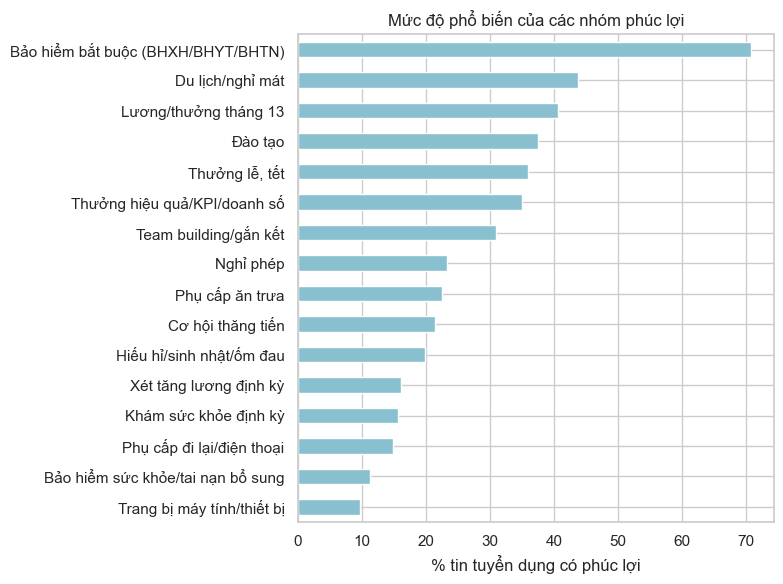

,% tin
benefit_tags,
Bảo hiểm bắt buộc (BHXH/BHYT/BHTN),70.9
Du lịch/nghỉ mát,43.8
Lương/thưởng tháng 13,40.7
Đào tạo,37.5
"Thưởng lễ, tết",35.9
Thưởng hiệu quả/KPI/doanh số,35.0
Team building/gắn kết,31.0
Nghỉ phép,23.3
Phụ cấp ăn trưa,22.6


In [2]:
from scipy.stats import spearmanr
from src.taxonomy import BENEFIT_GROUPS, tag_items
df["benefit_tags"] = df["benefits_list"].map(lambda l: tag_items(l, BENEFIT_GROUPS))
df["n_benefit_groups"] = df["benefit_tags"].map(len)
print(f"Tin có ít nhất 1 nhóm phúc lợi nhận diện được: {(df.n_benefit_groups > 0).mean():.1%}")
share = df["benefit_tags"].explode().value_counts() / len(df) * 100
fig, ax = plt.subplots(figsize=(8, 6))
share.sort_values().plot.barh(ax=ax, color="#88c0d0")
ax.set(xlabel="% tin tuyển dụng có phúc lợi", ylabel="", title="Mức độ phổ biến của các nhóm phúc lợi")
savefig("q4_benefit_share.png")
share.round(1).to_frame("% tin")

## Phúc lợi theo nhóm lương

            min    max  size
salary_q                    
Q1 (thấp)   1.0   10.0  7112
Q2         11.0   13.0  6903
Q3         14.0   17.0  5772
Q4 (cao)   18.0  200.0  6009


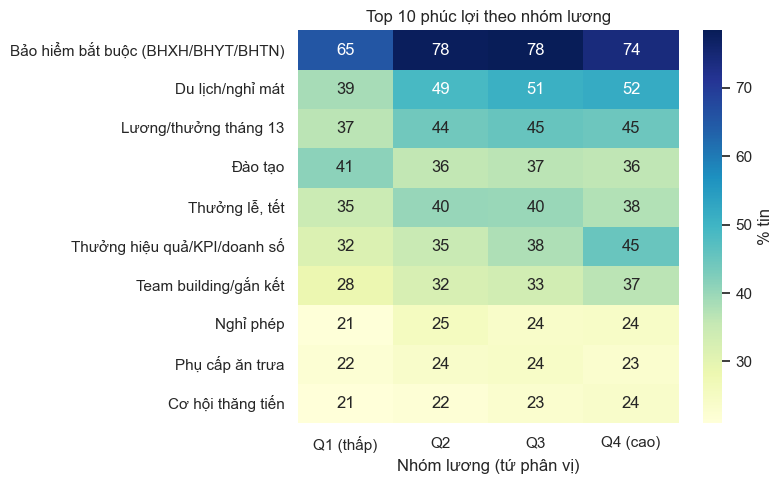

In [3]:
s = df[~df.salary_negotiable & ~df.salary_outlier].copy()
s["salary_q"] = pd.qcut(s["salary_avg_num"], 4, labels=["Q1 (thấp)", "Q2", "Q3", "Q4 (cao)"])
print(s.groupby("salary_q", observed=True)["salary_avg_num"].agg(["min", "max", "size"]))
onehot = pd.DataFrame({b: s["benefit_tags"].map(lambda t, b=b: b in t) for b in share.index[:10]})
by_q = onehot.groupby(s["salary_q"], observed=True).mean().T * 100
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(by_q, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "% tin"})
ax.set(xlabel="Nhóm lương (tứ phân vị)", ylabel="", title="Top 10 phúc lợi theo nhóm lương")
savefig("q4_benefits_by_salary_quartile.png")

Spearman(số nhóm phúc lợi, lương) = 0.140, p = 5.0e-113


,TB số nhóm phúc lợi
salary_negotiable,
Công bố lương,4.65
Thoả thuận,4.14


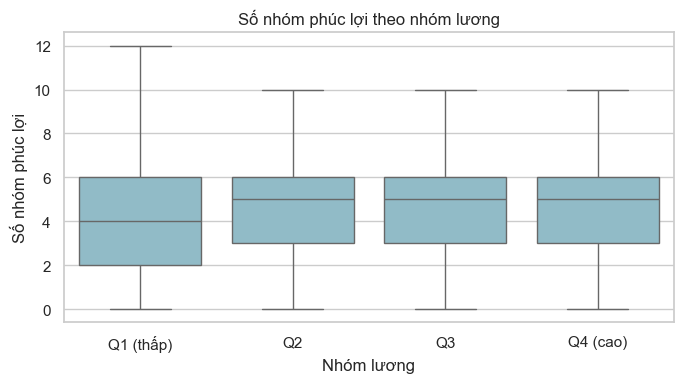

In [4]:
rho, p = spearmanr(s["n_benefit_groups"], s["salary_avg_num"])
print(f"Spearman(số nhóm phúc lợi, lương) = {rho:.3f}, p = {p:.1e}")
cmp = df.groupby("salary_negotiable")["n_benefit_groups"].mean().rename({True: "Thoả thuận", False: "Công bố lương"})
display(cmp.round(2).to_frame("TB số nhóm phúc lợi"))
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=s, x="salary_q", y="n_benefit_groups", ax=ax, color="#88c0d0", showfliers=False)
ax.set(xlabel="Nhóm lương", ylabel="Số nhóm phúc lợi", title="Số nhóm phúc lợi theo nhóm lương")
savefig("q4_n_benefits_by_salary.png")

## Kết luận

In [5]:
diff = (by_q["Q4 (cao)"] - by_q["Q1 (thấp)"]).sort_values()
print(f"- Phổ biến nhất: {share.index[0]} ({share.iloc[0]:.0f}% tin), {share.index[1]} ({share.iloc[1]:.0f}%), {share.index[2]} ({share.iloc[2]:.0f}%).")
strength = "rất yếu" if abs(rho) < 0.1 else "yếu" if abs(rho) < 0.3 else "vừa"
print(f"- Tương quan số nhóm phúc lợi – lương: ρ = {rho:.2f} ({strength}, {'dương' if rho > 0 else 'âm'}).")
print(f"- Chênh lệch lớn nhất giữa nhóm lương cao và thấp: '{diff.index[-1]}' ({diff.iloc[-1]:+.0f} điểm %); "
      f"'{diff.index[0]}' ({diff.iloc[0]:+.0f} điểm %).")

- Phổ biến nhất: Bảo hiểm bắt buộc (BHXH/BHYT/BHTN) (71% tin), Du lịch/nghỉ mát (44%), Lương/thưởng tháng 13 (41%).
- Tương quan số nhóm phúc lợi – lương: ρ = 0.14 (yếu, dương).
- Chênh lệch lớn nhất giữa nhóm lương cao và thấp: 'Thưởng hiệu quả/KPI/doanh số' (+13 điểm %); 'Đào tạo' (-5 điểm %).


**Hạn chế chung:** dữ liệu chỉ từ TopCV (2025), là **lương đăng tuyển** (không phải lương thực nhận),
và ~29% tin không công bố lương. Kết luận chỉ mô tả thị trường tin tuyển dụng trên nền tảng này.

Phúc lợi chỉ được đếm khi khớp regex — có thể bỏ sót cách viết hiếm.
*Nhận xét trên được sinh tự động từ số liệu — thành viên phụ trách cần đọc lại và diễn giải bằng lời của mình.*